## Flight Price Prediction(EDA + Feature Engineering)

In [1]:
## Dataset: https://github.com/krishnaik06/5-Days-Live-EDA-and-Feature-Engineering/tree/main/Flight%20Prediction

In [2]:
#importing basics libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

In [3]:
train_df=pd.read_excel('Data_Train.xlsx')
train_df.head()

,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price
0,IndiGo,24/03/2019,Banglore,New Delhi,BLR → DEL,22:20,01:10 22 Mar,2h 50m,non-stop,No info,3897
1,Air India,1/05/2019,Kolkata,Banglore,CCU → IXR → BBI → BLR,05:50,13:15,7h 25m,2 stops,No info,7662
2,Jet Airways,9/06/2019,Delhi,Cochin,DEL → LKO → BOM → COK,09:25,04:25 10 Jun,19h,2 stops,No info,13882
3,IndiGo,12/05/2019,Kolkata,Banglore,CCU → NAG → BLR,18:05,23:30,5h 25m,1 stop,No info,6218
4,IndiGo,01/03/2019,Banglore,New Delhi,BLR → NAG → DEL,16:50,21:35,4h 45m,1 stop,No info,13302


In [4]:
test_df=pd.read_excel('Test_set.xlsx')
test_df.head()

,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info
0,Jet Airways,6/06/2019,Delhi,Cochin,DEL → BOM → COK,17:30,04:25 07 Jun,10h 55m,1 stop,No info
1,IndiGo,12/05/2019,Kolkata,Banglore,CCU → MAA → BLR,06:20,10:20,4h,1 stop,No info
2,Jet Airways,21/05/2019,Delhi,Cochin,DEL → BOM → COK,19:15,19:00 22 May,23h 45m,1 stop,In-flight meal not included
3,Multiple carriers,21/05/2019,Delhi,Cochin,DEL → BOM → COK,08:00,21:00,13h,1 stop,No info
4,Air Asia,24/06/2019,Banglore,Delhi,BLR → DEL,23:55,02:45 25 Jun,2h 50m,non-stop,No info


In [5]:
# Instead of: final_df = train_df.append(test_df)
final_df = pd.concat([train_df, test_df], ignore_index=True)
final_df.head()

,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price
0,IndiGo,24/03/2019,Banglore,New Delhi,BLR → DEL,22:20,01:10 22 Mar,2h 50m,non-stop,No info,3897.0
1,Air India,1/05/2019,Kolkata,Banglore,CCU → IXR → BBI → BLR,05:50,13:15,7h 25m,2 stops,No info,7662.0
2,Jet Airways,9/06/2019,Delhi,Cochin,DEL → LKO → BOM → COK,09:25,04:25 10 Jun,19h,2 stops,No info,13882.0
3,IndiGo,12/05/2019,Kolkata,Banglore,CCU → NAG → BLR,18:05,23:30,5h 25m,1 stop,No info,6218.0
4,IndiGo,01/03/2019,Banglore,New Delhi,BLR → NAG → DEL,16:50,21:35,4h 45m,1 stop,No info,13302.0


In [6]:
final_df.tail()

,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price
13349,Air India,6/06/2019,Kolkata,Banglore,CCU → DEL → BLR,20:30,20:25 07 Jun,23h 55m,1 stop,No info,NaN
13350,IndiGo,27/03/2019,Kolkata,Banglore,CCU → BLR,14:20,16:55,2h 35m,non-stop,No info,NaN
13351,Jet Airways,6/03/2019,Delhi,Cochin,DEL → BOM → COK,21:50,04:25 07 Mar,6h 35m,1 stop,No info,NaN
13352,Air India,6/03/2019,Delhi,Cochin,DEL → BOM → COK,04:00,19:15,15h 15m,1 stop,No info,NaN
13353,Multiple carriers,15/06/2019,Delhi,Cochin,DEL → BOM → COK,04:55,19:15,14h 20m,1 stop,No info,NaN


In [7]:
final_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 13354 entries, 0 to 13353
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Airline          13354 non-null  str    
 1   Date_of_Journey  13354 non-null  str    
 2   Source           13354 non-null  str    
 3   Destination      13354 non-null  str    
 4   Route            13353 non-null  str    
 5   Dep_Time         13354 non-null  str    
 6   Arrival_Time     13354 non-null  str    
 7   Duration         13354 non-null  str    
 8   Total_Stops      13353 non-null  str    
 9   Additional_Info  13354 non-null  str    
 10  Price            10683 non-null  float64
dtypes: float64(1), str(10)
memory usage: 1.1 MB


.str.split('/') -> Splits each string at every /  ->  ['24', '12', '2026']
.str[0] -> Accesses index 0 of that list -> '24'
.str[2] -> Accesses index 2 of that list -> '2026'

In [8]:
##Fetaure Engineering Process
final_df['Date']=final_df['Date_of_Journey'].str.split('/').str[0]
final_df['Month']=final_df['Date_of_Journey'].str.split('/').str[1]
final_df['Year']=final_df['Date_of_Journey'].str.split('/').str[2]

In [9]:
final_df.head(10)

,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price,Date,Month,Year
0,IndiGo,24/03/2019,Banglore,New Delhi,BLR → DEL,22:20,01:10 22 Mar,2h 50m,non-stop,No info,3897.0,24,03,2019
1,Air India,1/05/2019,Kolkata,Banglore,CCU → IXR → BBI → BLR,05:50,13:15,7h 25m,2 stops,No info,7662.0,1,05,2019
2,Jet Airways,9/06/2019,Delhi,Cochin,DEL → LKO → BOM → COK,09:25,04:25 10 Jun,19h,2 stops,No info,13882.0,9,06,2019
3,IndiGo,12/05/2019,Kolkata,Banglore,CCU → NAG → BLR,18:05,23:30,5h 25m,1 stop,No info,6218.0,12,05,2019
4,IndiGo,01/03/2019,Banglore,New Delhi,BLR → NAG → DEL,16:50,21:35,4h 45m,1 stop,No info,13302.0,01,03,2019
5,SpiceJet,24/06/2019,Kolkata,Banglore,CCU → BLR,09:00,11:25,2h 25m,non-stop,No info,3873.0,24,06,2019
6,Jet Airways,12/03/2019,Banglore,New Delhi,BLR → BOM → DEL,18:55,10:25 13 Mar,15h 30m,1 stop,In-flight meal not included,11087.0,12,03,2019
7,Jet Airways,01/03/2019,Banglore,New Delhi,BLR → BOM → DEL,08:00,05:05 02 Mar,21h 5m,1 stop,No info,22270.0,01,03,2019
8,Jet Airways,12/03/2019,Banglore,New Delhi,BLR → BOM → DEL,08:55,10:25 13 Mar,25h 30m,1 stop,In-flight meal not included,11087.0,12,03,2019
9,Multiple carriers,27/05/2019,Delhi,Cochin,DEL → BOM → COK,11:25,19:15,7h 50m,1 stop,No info,8625.0,27,05,2019


In [10]:
final_df['Date']=final_df['Date'].astype(int)
final_df['Month']=final_df['Month'].astype(int)
final_df['Year']=final_df['Year'].astype(int)

In [11]:
final_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 13354 entries, 0 to 13353
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Airline          13354 non-null  str    
 1   Date_of_Journey  13354 non-null  str    
 2   Source           13354 non-null  str    
 3   Destination      13354 non-null  str    
 4   Route            13353 non-null  str    
 5   Dep_Time         13354 non-null  str    
 6   Arrival_Time     13354 non-null  str    
 7   Duration         13354 non-null  str    
 8   Total_Stops      13353 non-null  str    
 9   Additional_Info  13354 non-null  str    
 10  Price            10683 non-null  float64
 11  Date             13354 non-null  int64  
 12  Month            13354 non-null  int64  
 13  Year             13354 non-null  int64  
dtypes: float64(1), int64(3), str(10)
memory usage: 1.4 MB


In [12]:
final_df.drop('Date_of_Journey',axis=1,inplace=True)

In [13]:
final_df.head(10)

,Airline,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price,Date,Month,Year
0,IndiGo,Banglore,New Delhi,BLR → DEL,22:20,01:10 22 Mar,2h 50m,non-stop,No info,3897.0,24,3,2019
1,Air India,Kolkata,Banglore,CCU → IXR → BBI → BLR,05:50,13:15,7h 25m,2 stops,No info,7662.0,1,5,2019
2,Jet Airways,Delhi,Cochin,DEL → LKO → BOM → COK,09:25,04:25 10 Jun,19h,2 stops,No info,13882.0,9,6,2019
3,IndiGo,Kolkata,Banglore,CCU → NAG → BLR,18:05,23:30,5h 25m,1 stop,No info,6218.0,12,5,2019
4,IndiGo,Banglore,New Delhi,BLR → NAG → DEL,16:50,21:35,4h 45m,1 stop,No info,13302.0,1,3,2019
5,SpiceJet,Kolkata,Banglore,CCU → BLR,09:00,11:25,2h 25m,non-stop,No info,3873.0,24,6,2019
6,Jet Airways,Banglore,New Delhi,BLR → BOM → DEL,18:55,10:25 13 Mar,15h 30m,1 stop,In-flight meal not included,11087.0,12,3,2019
7,Jet Airways,Banglore,New Delhi,BLR → BOM → DEL,08:00,05:05 02 Mar,21h 5m,1 stop,No info,22270.0,1,3,2019
8,Jet Airways,Banglore,New Delhi,BLR → BOM → DEL,08:55,10:25 13 Mar,25h 30m,1 stop,In-flight meal not included,11087.0,12,3,2019
9,Multiple carriers,Delhi,Cochin,DEL → BOM → COK,11:25,19:15,7h 50m,1 stop,No info,8625.0,27,5,2019


In [14]:
final_df['Arrival_Time'].str.split(' ').str[0]

0        01:10
1        13:15
2        04:25
3        23:30
4        21:35
         ...  
13349    20:25
13350    16:55
13351    04:25
13352    19:15
13353    19:15
Name: Arrival_Time, Length: 13354, dtype: object

In [15]:
final_df['Arrival_Time']=final_df['Arrival_Time'].apply(lambda x : x.split(' ')[0])

In [16]:
final_df['Arrival_hour']=final_df['Arrival_Time'].str.split(':').str[0]
final_df['Arrival_min']=final_df['Arrival_Time'].str.split(':').str[1]

In [17]:
final_df.head(10)

,Airline,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price,Date,Month,Year,Arrival_hour,Arrival_min
0,IndiGo,Banglore,New Delhi,BLR → DEL,22:20,01:10,2h 50m,non-stop,No info,3897.0,24,3,2019,01,10
1,Air India,Kolkata,Banglore,CCU → IXR → BBI → BLR,05:50,13:15,7h 25m,2 stops,No info,7662.0,1,5,2019,13,15
2,Jet Airways,Delhi,Cochin,DEL → LKO → BOM → COK,09:25,04:25,19h,2 stops,No info,13882.0,9,6,2019,04,25
3,IndiGo,Kolkata,Banglore,CCU → NAG → BLR,18:05,23:30,5h 25m,1 stop,No info,6218.0,12,5,2019,23,30
4,IndiGo,Banglore,New Delhi,BLR → NAG → DEL,16:50,21:35,4h 45m,1 stop,No info,13302.0,1,3,2019,21,35
5,SpiceJet,Kolkata,Banglore,CCU → BLR,09:00,11:25,2h 25m,non-stop,No info,3873.0,24,6,2019,11,25
6,Jet Airways,Banglore,New Delhi,BLR → BOM → DEL,18:55,10:25,15h 30m,1 stop,In-flight meal not included,11087.0,12,3,2019,10,25
7,Jet Airways,Banglore,New Delhi,BLR → BOM → DEL,08:00,05:05,21h 5m,1 stop,No info,22270.0,1,3,2019,05,05
8,Jet Airways,Banglore,New Delhi,BLR → BOM → DEL,08:55,10:25,25h 30m,1 stop,In-flight meal not included,11087.0,12,3,2019,10,25
9,Multiple carriers,Delhi,Cochin,DEL → BOM → COK,11:25,19:15,7h 50m,1 stop,No info,8625.0,27,5,2019,19,15


In [18]:
final_df['Arrival_hour']=final_df['Arrival_hour'].astype(int)
final_df['Arrival_min']=final_df['Arrival_min'].astype(int)

In [19]:
final_df.drop('Arrival_Time',axis=1,inplace=True)

In [20]:
final_df.head(5)

,Airline,Source,Destination,Route,Dep_Time,Duration,Total_Stops,Additional_Info,Price,Date,Month,Year,Arrival_hour,Arrival_min
0,IndiGo,Banglore,New Delhi,BLR → DEL,22:20,2h 50m,non-stop,No info,3897.0,24,3,2019,1,10
1,Air India,Kolkata,Banglore,CCU → IXR → BBI → BLR,05:50,7h 25m,2 stops,No info,7662.0,1,5,2019,13,15
2,Jet Airways,Delhi,Cochin,DEL → LKO → BOM → COK,09:25,19h,2 stops,No info,13882.0,9,6,2019,4,25
3,IndiGo,Kolkata,Banglore,CCU → NAG → BLR,18:05,5h 25m,1 stop,No info,6218.0,12,5,2019,23,30
4,IndiGo,Banglore,New Delhi,BLR → NAG → DEL,16:50,4h 45m,1 stop,No info,13302.0,1,3,2019,21,35


In [21]:
final_df['Dept_hour']=final_df['Dep_Time'].str.split(':').str[0]
final_df['Dept_min']=final_df['Dep_Time'].str.split(':').str[1]
final_df['Dept_hour']=final_df['Dept_hour'].astype(int)
final_df['Dept_min']=final_df['Dept_min'].astype(int)
final_df.drop('Dep_Time',axis=1,inplace=True)

In [22]:
final_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 13354 entries, 0 to 13353
Data columns (total 15 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Airline          13354 non-null  str    
 1   Source           13354 non-null  str    
 2   Destination      13354 non-null  str    
 3   Route            13353 non-null  str    
 4   Duration         13354 non-null  str    
 5   Total_Stops      13353 non-null  str    
 6   Additional_Info  13354 non-null  str    
 7   Price            10683 non-null  float64
 8   Date             13354 non-null  int64  
 9   Month            13354 non-null  int64  
 10  Year             13354 non-null  int64  
 11  Arrival_hour     13354 non-null  int64  
 12  Arrival_min      13354 non-null  int64  
 13  Dept_hour        13354 non-null  int64  
 14  Dept_min         13354 non-null  int64  
dtypes: float64(1), int64(7), str(7)
memory usage: 1.5 MB


## Mapping and classifying

In [23]:
final_df['Total_Stops'].unique()

<StringArray>
['non-stop', '2 stops', '1 stop', '3 stops', nan, '4 stops']
Length: 6, dtype: str

In [24]:
final_df['Total_Stops']=final_df['Total_Stops'].map({'non-stop':0,'1 stop':1,'2 stops':2,'3 stops':3,'4 stops':4})

In [25]:
# nan is educated guess cuz flight be doing 1 stop for them paths
final_df['Total_Stops'] = final_df['Total_Stops'].fillna(1)
# .fillna() fills missing values, leaving existing values intact
# .map() on NaN keeps the unmapped existing value as NaN

In [26]:
final_df[final_df['Total_Stops'].isnull()]

,Airline,Source,Destination,Route,Duration,Total_Stops,Additional_Info,Price,Date,Month,Year,Arrival_hour,Arrival_min,Dept_hour,Dept_min


In [27]:
final_df.drop('Route', axis=1, inplace=True)
final_df.head()

,Airline,Source,Destination,Duration,Total_Stops,Additional_Info,Price,Date,Month,Year,Arrival_hour,Arrival_min,Dept_hour,Dept_min
0,IndiGo,Banglore,New Delhi,2h 50m,0.0,No info,3897.0,24,3,2019,1,10,22,20
1,Air India,Kolkata,Banglore,7h 25m,2.0,No info,7662.0,1,5,2019,13,15,5,50
2,Jet Airways,Delhi,Cochin,19h,2.0,No info,13882.0,9,6,2019,4,25,9,25
3,IndiGo,Kolkata,Banglore,5h 25m,1.0,No info,6218.0,12,5,2019,23,30,18,5
4,IndiGo,Banglore,New Delhi,4h 45m,1.0,No info,13302.0,1,3,2019,21,35,16,50


In [28]:
final_df['Additional_Info'].unique()

<StringArray>
[                     'No info',  'In-flight meal not included',
 'No check-in baggage included',              '1 Short layover',
                      'No Info',               '1 Long layover',
              'Change airports',               'Business class',
               'Red-eye flight',               '2 Long layover']
Length: 10, dtype: str

### Can be done with Additional_Info:

In [29]:
final_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 13354 entries, 0 to 13353
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Airline          13354 non-null  str    
 1   Source           13354 non-null  str    
 2   Destination      13354 non-null  str    
 3   Duration         13354 non-null  str    
 4   Total_Stops      13354 non-null  float64
 5   Additional_Info  13354 non-null  str    
 6   Price            10683 non-null  float64
 7   Date             13354 non-null  int64  
 8   Month            13354 non-null  int64  
 9   Year             13354 non-null  int64  
 10  Arrival_hour     13354 non-null  int64  
 11  Arrival_min      13354 non-null  int64  
 12  Dept_hour        13354 non-null  int64  
 13  Dept_min         13354 non-null  int64  
dtypes: float64(2), int64(7), str(5)
memory usage: 1.4 MB


In [30]:
final_df['duration_hour']=final_df['Duration'].str.split(' ').str[0].str.split('h').str[0]
final_df['duration_min']=final_df['Duration'].str.split(' ').str[1].str.split('m').str[0]
final_df.head(10)

,Airline,Source,Destination,Duration,Total_Stops,Additional_Info,Price,Date,Month,Year,Arrival_hour,Arrival_min,Dept_hour,Dept_min,duration_hour,duration_min
0,IndiGo,Banglore,New Delhi,2h 50m,0.0,No info,3897.0,24,3,2019,1,10,22,20,2,50
1,Air India,Kolkata,Banglore,7h 25m,2.0,No info,7662.0,1,5,2019,13,15,5,50,7,25
2,Jet Airways,Delhi,Cochin,19h,2.0,No info,13882.0,9,6,2019,4,25,9,25,19,NaN
3,IndiGo,Kolkata,Banglore,5h 25m,1.0,No info,6218.0,12,5,2019,23,30,18,5,5,25
4,IndiGo,Banglore,New Delhi,4h 45m,1.0,No info,13302.0,1,3,2019,21,35,16,50,4,45
5,SpiceJet,Kolkata,Banglore,2h 25m,0.0,No info,3873.0,24,6,2019,11,25,9,0,2,25
6,Jet Airways,Banglore,New Delhi,15h 30m,1.0,In-flight meal not included,11087.0,12,3,2019,10,25,18,55,15,30
7,Jet Airways,Banglore,New Delhi,21h 5m,1.0,No info,22270.0,1,3,2019,5,5,8,0,21,5
8,Jet Airways,Banglore,New Delhi,25h 30m,1.0,In-flight meal not included,11087.0,12,3,2019,10,25,8,55,25,30
9,Multiple carriers,Delhi,Cochin,7h 50m,1.0,No info,8625.0,27,5,2019,19,15,11,25,7,50


In [31]:
final_df[final_df['duration_hour'].isnull()]

,Airline,Source,Destination,Duration,Total_Stops,Additional_Info,Price,Date,Month,Year,Arrival_hour,Arrival_min,Dept_hour,Dept_min,duration_hour,duration_min


In [32]:
final_df['duration_min'] = final_df['duration_min'].fillna(0)
final_df.drop('Duration', axis=1, inplace=True)
final_df.head(10)

,Airline,Source,Destination,Total_Stops,Additional_Info,Price,Date,Month,Year,Arrival_hour,Arrival_min,Dept_hour,Dept_min,duration_hour,duration_min
0,IndiGo,Banglore,New Delhi,0.0,No info,3897.0,24,3,2019,1,10,22,20,2,50
1,Air India,Kolkata,Banglore,2.0,No info,7662.0,1,5,2019,13,15,5,50,7,25
2,Jet Airways,Delhi,Cochin,2.0,No info,13882.0,9,6,2019,4,25,9,25,19,0
3,IndiGo,Kolkata,Banglore,1.0,No info,6218.0,12,5,2019,23,30,18,5,5,25
4,IndiGo,Banglore,New Delhi,1.0,No info,13302.0,1,3,2019,21,35,16,50,4,45
5,SpiceJet,Kolkata,Banglore,0.0,No info,3873.0,24,6,2019,11,25,9,0,2,25
6,Jet Airways,Banglore,New Delhi,1.0,In-flight meal not included,11087.0,12,3,2019,10,25,18,55,15,30
7,Jet Airways,Banglore,New Delhi,1.0,No info,22270.0,1,3,2019,5,5,8,0,21,5
8,Jet Airways,Banglore,New Delhi,1.0,In-flight meal not included,11087.0,12,3,2019,10,25,8,55,25,30
9,Multiple carriers,Delhi,Cochin,1.0,No info,8625.0,27,5,2019,19,15,11,25,7,50


In [33]:
final_df[final_df['duration_hour']=='5m']

,Airline,Source,Destination,Total_Stops,Additional_Info,Price,Date,Month,Year,Arrival_hour,Arrival_min,Dept_hour,Dept_min,duration_hour,duration_min
6474,Air India,Mumbai,Hyderabad,2.0,No info,17327.0,6,3,2019,16,55,16,50,5m,0
13343,Air India,Mumbai,Hyderabad,2.0,No info,NaN,12,3,2019,16,55,16,50,5m,0


In [34]:
final_df.drop(6474,axis=0,inplace=True)
final_df.drop(13343,axis=0,inplace=True)

In [35]:
final_df['duration_hour']=final_df['duration_hour'].astype('int')
final_df['duration_min']=final_df['duration_min'].astype('int')

In [36]:
final_df['Airline'].unique()

<StringArray>
[                           'IndiGo',                         'Air India',
                       'Jet Airways',                          'SpiceJet',
                 'Multiple carriers',                             'GoAir',
                           'Vistara',                          'Air Asia',
           'Vistara Premium economy',              'Jet Airways Business',
 'Multiple carriers Premium economy',                            'Trujet']
Length: 12, dtype: str

In [37]:
final_df['Total_Stops']=final_df['Total_Stops'].astype('int')

In [38]:
final_df['duration_min'].describe()

count    13352.000000
mean        28.345192
std         16.904283
min          0.000000
25%         15.000000
50%         30.000000
75%         45.000000
max         55.000000
Name: duration_min, dtype: float64

In [39]:
final_df = pd.get_dummies(final_df, columns=["Airline", "Source", "Destination"], drop_first=True)

In [40]:
final_df.info()

<class 'pandas.DataFrame'>
Index: 13352 entries, 0 to 13353
Data columns (total 32 columns):
 #   Column                                     Non-Null Count  Dtype  
---  ------                                     --------------  -----  
 0   Total_Stops                                13352 non-null  int64  
 1   Additional_Info                            13352 non-null  str    
 2   Price                                      10682 non-null  float64
 3   Date                                       13352 non-null  int64  
 4   Month                                      13352 non-null  int64  
 5   Year                                       13352 non-null  int64  
 6   Arrival_hour                               13352 non-null  int64  
 7   Arrival_min                                13352 non-null  int64  
 8   Dept_hour                                  13352 non-null  int64  
 9   Dept_min                                   13352 non-null  int64  
 10  duration_hour                         

In [41]:
final_df.head(20)

,Total_Stops,Additional_Info,Price,Date,Month,Year,Arrival_hour,Arrival_min,Dept_hour,Dept_min,...,Airline_Vistara Premium economy,Source_Chennai,Source_Delhi,Source_Kolkata,Source_Mumbai,Destination_Cochin,Destination_Delhi,Destination_Hyderabad,Destination_Kolkata,Destination_New Delhi
0,0,No info,3897.0,24,3,2019,1,10,22,20,...,False,False,False,False,False,False,False,False,False,True
1,2,No info,7662.0,1,5,2019,13,15,5,50,...,False,False,False,True,False,False,False,False,False,False
2,2,No info,13882.0,9,6,2019,4,25,9,25,...,False,False,True,False,False,True,False,False,False,False
3,1,No info,6218.0,12,5,2019,23,30,18,5,...,False,False,False,True,False,False,False,False,False,False
4,1,No info,13302.0,1,3,2019,21,35,16,50,...,False,False,False,False,False,False,False,False,False,True
5,0,No info,3873.0,24,6,2019,11,25,9,0,...,False,False,False,True,False,False,False,False,False,False
6,1,In-flight meal not included,11087.0,12,3,2019,10,25,18,55,...,False,False,False,False,False,False,False,False,False,True
7,1,No info,22270.0,1,3,2019,5,5,8,0,...,False,False,False,False,False,False,False,False,False,True
8,1,In-flight meal not included,11087.0,12,3,2019,10,25,8,55,...,False,False,False,False,False,False,False,False,False,True
9,1,No info,8625.0,27,5,2019,19,15,11,25,...,False,False,True,False,False,True,False,False,False,False


In [42]:
final_df['Additional_Info'].unique()

<StringArray>
[                     'No info',  'In-flight meal not included',
 'No check-in baggage included',              '1 Short layover',
                      'No Info',               '1 Long layover',
              'Change airports',               'Business class',
               'Red-eye flight',               '2 Long layover']
Length: 10, dtype: str

In [43]:
final_df['Additional_Info'] = final_df['Additional_Info'].fillna('No info')
final_df['Additional_Info'] = final_df['Additional_Info'].replace({'No Info': 'No info'})
value_counts = final_df['Additional_Info'].value_counts(dropna=False)
value_percentages = final_df['Additional_Info'].value_counts(dropna=False, normalize=True) * 100
distribution_df = pd.DataFrame({
    'Row_Count': value_counts,
    'Percentage (%)': value_percentages.round(2)
})

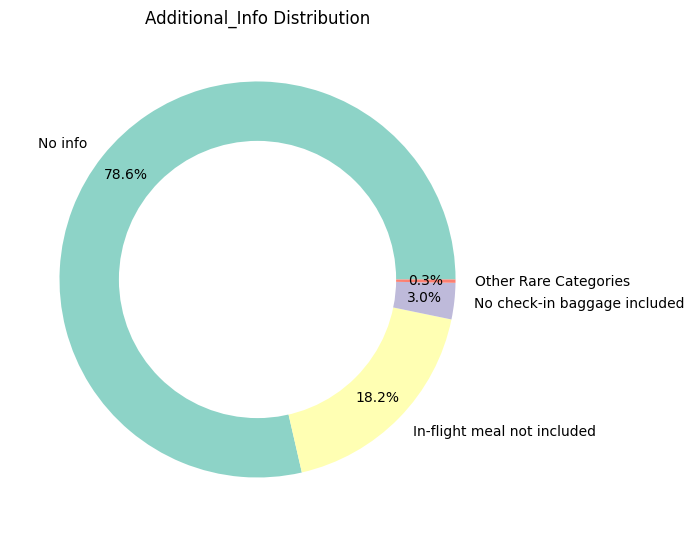

In [44]:
threshold = 50  # Rows below this count get grouped
df_grouped = distribution_df.copy()

rare_mask = df_grouped['Row_Count'] < threshold
if rare_mask.any():
    rare_sum = df_grouped.loc[rare_mask, 'Row_Count'].sum()
    df_grouped = df_grouped[~rare_mask]
    df_grouped.loc['Other Rare Categories'] = [rare_sum, (rare_sum / final_df.shape[0]) * 100]

# Plot Donut Chart
plt.figure(figsize=(7, 7))
plt.pie(
    df_grouped['Row_Count'], 
    labels=df_grouped.index, 
    autopct='%1.1f%%', 
    pctdistance=0.85,
    colors=sns.color_palette('Set3', len(df_grouped))
)

# Draw center circle for donut effect
centre_circle = plt.Circle((0,0), 0.70, fc='white')
plt.gca().add_artist(centre_circle)

plt.title('Additional_Info Distribution')
plt.tight_layout()
plt.show()

### We ignore Rare since them less and add lots of noise

In [45]:
final_df['has_meal_restriction'] = final_df['Additional_Info'].str.contains('meal', na=False).astype(int)
final_df['has_baggage_restriction'] = final_df['Additional_Info'].str.contains('baggage', na=False).astype(int)
final_df['has_layover_info'] = final_df['Additional_Info'].str.contains('layover', na=False).astype(int)
final_df.head()

,Total_Stops,Additional_Info,Price,Date,Month,Year,Arrival_hour,Arrival_min,Dept_hour,Dept_min,...,Source_Kolkata,Source_Mumbai,Destination_Cochin,Destination_Delhi,Destination_Hyderabad,Destination_Kolkata,Destination_New Delhi,has_meal_restriction,has_baggage_restriction,has_layover_info
0,0,No info,3897.0,24,3,2019,1,10,22,20,...,False,False,False,False,False,False,True,0,0,0
1,2,No info,7662.0,1,5,2019,13,15,5,50,...,True,False,False,False,False,False,False,0,0,0
2,2,No info,13882.0,9,6,2019,4,25,9,25,...,False,False,True,False,False,False,False,0,0,0
3,1,No info,6218.0,12,5,2019,23,30,18,5,...,True,False,False,False,False,False,False,0,0,0
4,1,No info,13302.0,1,3,2019,21,35,16,50,...,False,False,False,False,False,False,True,0,0,0


In [46]:
final_df.drop('Additional_Info', axis=1, inplace=True)

## Save Cleaned Data
Exporting so the training notebook can load it directly, without re-running cleaning.

In [ ]:
final_df.to_csv('processed_data.csv', index=False)
print(f"Saved processed_data.csv with shape: {final_df.shape}")